# IBM Q 5-qubit "bowtie" (ibmqx2 Yorktown / ibmqx4 Tenerife): a Quantcore-PDK rebuild, step by step

**What the chip is.** IBM's first cloud processor (2016–2021): five fixed-frequency transmons and two bus resonators,
each bus coupling three qubits — Q0, Q1, Q2 on one, Q2, Q3, Q4 on the other — so the coupling graph is two triangles
sharing Q2 (the *bowtie*). Each qubit has its own readout resonator, read and driven through its own line; two-qubit
gates are cross-resonance gates on the bus-mediated exchange J.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica** (spec `docs/designs/ibm/ibm_bowtie_5q.md`).
No layout of the chip is public; IBM's published device data set the topology and the targets, the layout is ours:
Quantum Metal's `TransmonPocket6` (IBM's floating two-pad pocket transmon, through `metal:`) with **Quantcore trilayer
junctions** sized per qubit by the PDK junction rule, qcc meander routes for the buses and readouts, a `LineTee` fork
that lets one λ/2 bus reach three qubits, KQC finger capacitors, Quantcore `BondPad`s, the PDK die frame (9 × 8 mm,
QCT), sapphire 650 µm (εr 10.25), and the qcc LOM.

| | from the source | adapted here (why) |
|---|---|---|
| topology | coupling map 0-1, 0-2, 1-2, 2-3, 2-4, 3-4; two buses (Q0, Q1, Q2) and (Q2, Q3, Q4); one readout per qubit, individual lines | each bus is a λ/2 line from Q2 to a tee whose two short stubs reach the other two qubits (both ends at a voltage antinode) |
| f_q, α, J | ibmqx2 Hamiltonian / properties (Qiskit `FakeYorktown`, 2021-03-15): f_q 5.033–5.292 GHz, α −330 … −376 MHz, J 1.24–2.01 MHz | f_q matched per qubit with its junction; α ≈ −145 MHz (R_n ≤ 50 kΩ caps L_J ≤ 7.5 nH, so C_Σ is larger at the same f_q); J from the bus coupling pads. Step 13 tries the two alternatives (#49) |
| buses | 7.0 GHz (Q0, Q1, Q2) and 6.6 GHz (Q2, Q3, Q4) (ibmqx4, arXiv:1805.10478 citing IBM's backend README) | the same targets |
| readout | ibmqx2 measurement LO 6.437–6.579 GHz (ibmqx4 table: 6.439–6.580 GHz, χ 408–512 kHz) | λ/2 resonators to a series finger capacitor and a 50 Ω pad, one per qubit |
| junctions | Al/AlOx (not given) | Quantcore Nb/AlOx/Nb trilayer junctions, R_n 40–50 kΩ (PDK rule: Δ 1.4 meV) |
| pads | (no layout) | **PDK pad rule**: five bond pads, each etch `frame.pad_edge` = 100 µm from the die edge (`edge="auto"`) |
| placement | (no layout) | Q2 at the die centre; the layout is symmetric, so the content is centred (step 6) |
| cheese | (no layout to take it from) | **PDK band** (`cheese: "auto"`): no original cheese exists |

**Licences.** The device data come from `qiskit-ibm-runtime` (Apache-2.0; local copy
`build/external/qiskit_fake_backends/`) and the cited papers; the layout and code are ours (GPL, as the repository).

## 1 · Setup and the PDK

The notebook runs from the repository root; `_common` holds the table, snapshot, coupling and PDK helpers. `LIVE`
follows `QCC_LIVE` (live KLayout, or headless snapshots with `QCC_LIVE=0`).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, coupling and PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/ibm")

The PDK facts this chip relies on; the library applies each of them (frame and cheese in the build, the pad rule
through `edge=`, the junctions through `trilayer_junction`, the margins as DRC design warnings).

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**Source targets**: ibmqx2 (Qiskit `FakeYorktown` conf/props, 2021-03-15; the Hamiltonian's variables ÷ 2π) and the
ibmqx4 bus frequencies.

In [3]:
F_Q = {"Q0": 5.2823, "Q1": 5.2475, "Q2": 5.0334, "Q3": 5.2920, "Q4": 5.0785}          # GHz
ALPHA = {"Q0": -330.8, "Q1": -330.4, "Q2": -376.1, "Q3": -329.7, "Q4": -333.1}        # MHz
F_RO = {"Q0": 6.5304, "Q1": 6.4817, "Q2": 6.4365, "Q3": 6.5789, "Q4": 6.5301}        # GHz, meas LO centres
J_SRC = {"Q0-Q1": 1.905, "Q0-Q2": 1.820, "Q1-Q2": 1.236, "Q2-Q3": 1.820, "Q2-Q4": 1.812, "Q3-Q4": 2.009}  # MHz
F_BUS = {"BusA": 7.0, "BusB": 6.6}               # GHz (ibmqx4: Q0-Q1-Q2 bus 7.0, Q2-Q3-Q4 bus 6.6)

## 2 · The die and the frame

A 9 × 8 mm die (five readout pads on the top and bottom edges, the bowtie in between). The build draws the PDK frame
round it: dicing L's (1000/0), alignment grids (1001/0), chip boundary (100/0), the device ID `IBM5Q` on a free edge.

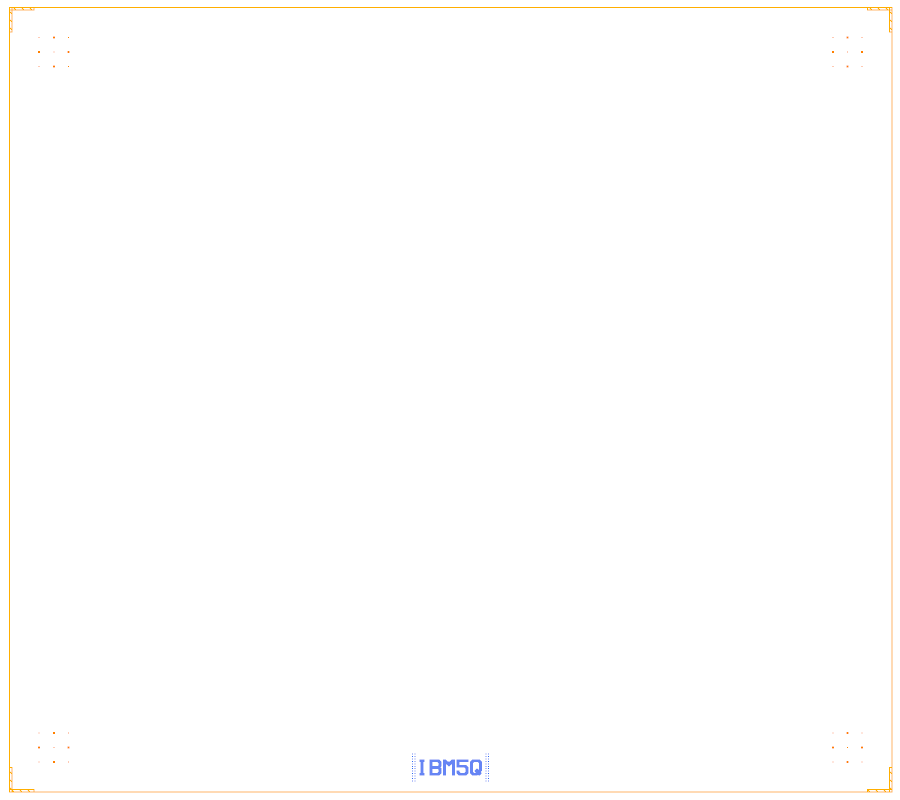

In [4]:
W, H = 9000, 8000
XC, YC = 4500, 4000                              # Q2 at the die centre
DX = 2100                                        # Q2 ↔ the outer qubits in x
d = Designer("ibm_bowtie_5q", box=(0, 0, W, H), chip={"name_chip": "IBM5Q"}, live=LIVE)
snap(d, OUT / "ibm_bowtie_5q_die.png", size=(900, 800), width=320);

## 3 · Pads: the PDK pad rule

One 50 Ω `BondPad` per qubit readout: Q0 and Q3 read out through the top edge, Q1, Q2 and Q4 through the bottom edge,
each in line with its qubit. The PDK puts every pad's outer etch edge **`frame.pad_edge` = 100 µm from the die
edge**; `edge="auto"` slides each pad perpendicular to its nearest edge until that holds, keeping its position along
the edge.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_Q0 | `BondPad` | n | 100.0 | ✓ |
| P_Q1 | `BondPad` | s | 100.0 | ✓ |
| P_Q2 | `BondPad` | s | 100.0 | ✓ |
| P_Q3 | `BondPad` | n | 100.0 | ✓ |
| P_Q4 | `BondPad` | s | 100.0 | ✓ |

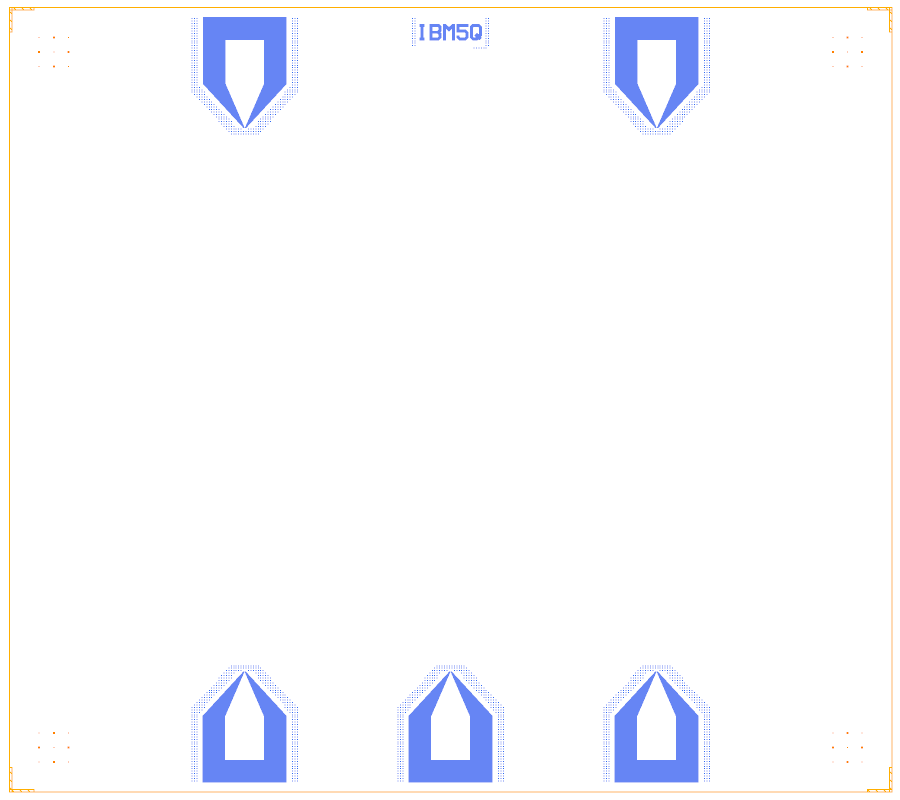

In [5]:
UP = ("Q0", "Q3")                                # read out through the top edge
X = {"Q0": XC - DX, "Q1": XC - DX, "Q2": XC, "Q3": XC + DX, "Q4": XC + DX}
Y_PAD = {n: H - 1150 if n in UP else 1150 for n in X}
bp = {n: d.add(f"P_{n}", "BondPad", at=(X[n], Y_PAD[n]), rot=180 if n in UP else 0, edge="auto") for n in X}
rebuild(d)
display(Markdown(pads_md(d)))
snap(d, OUT / "ibm_bowtie_5q_pads.png", size=(900, 800), width=320);

## 4 · Components: pockets, trilayer junctions, tees and finger capacitors

**Junctions.** One Quantcore trilayer junction per qubit, its L_J solved with the LOM (step 9 a) so that f_q lands on
IBM's frequency. `trilayer_junction(cell, lj_nH)` returns the cell parameters that draw it (fingers on 2/0 + 4/0,
spacer 50/0 with the 51–53/0 gradient) and the values the LOM uses; all five R_n are inside the PDK window.

In [6]:
LJ = {"Q0": 6.09, "Q1": 6.18, "Q2": 6.59, "Q3": 6.07, "Q4": 6.63}                   # nH
JUNCTIONS = {q: trilayer_junction("metal:TransmonPocket6", lj_nH=lj) for q, lj in LJ.items()}
for q, (p, j) in JUNCTIONS.items():
    print(q, p["junction_params"], "→ drawn", j, f"R_n {rn_from_lj(j['Lj_nH']) / 1e3:.1f} kΩ")

Q0 {'lj_nH': 6.09} → drawn {'Lj_nH': 6.1222, 'Cj_fF': 16.5} R_n 40.9 kΩ
Q1 {'lj_nH': 6.18} → drawn {'Lj_nH': 6.2356, 'Cj_fF': 16.2} R_n 41.7 kΩ
Q2 {'lj_nH': 6.59} → drawn {'Lj_nH': 6.6024, 'Cj_fF': 15.3} R_n 44.1 kΩ
Q3 {'lj_nH': 6.07} → drawn {'Lj_nH': 6.1222, 'Cj_fF': 16.5} R_n 40.9 kΩ
Q4 {'lj_nH': 6.63} → drawn {'Lj_nH': 6.6024, 'Cj_fF': 15.3} R_n 44.1 kΩ


**The pockets.** IBM's floating two-pad transmon: 750 × 160 µm pads, a 20 µm gap, in a 950 µm pocket (C_Σ ≈ 140 fF in
the LOM). Connection pads on the pad edges: bus pads 150 µm wide (they set J), readout pads 140 µm (they set χ). Q2
has two bus pads (west, east) at its top and its readout at the bottom; the outer qubits face their tee.

In [7]:
POCKET = dict(pad_width=750, pad_height=160, pad_gap=20, pocket_width=950, pocket_height=950)
BUS_PAD, RO_PAD = 150, 140                       # connection pad widths: bus (sets J), readout (sets χ)
YT = YC + 190                                    # the buses run straight at Q2's bus-pad height
STUB = 150                                       # tee → outer qubit stub
cpad = lambda name, loc_w, loc_h, width: {name: {"loc_W": loc_w, "loc_H": loc_h, "pad_width": width}}
yo = YT + 50 + STUB + 575                        # outer qubits: their bus pin sits STUB above / below the tee
place = {"Q0": (XC - DX, yo, {**cpad("bus", 0, -1, BUS_PAD), **cpad("ro", 0, 1, RO_PAD)}),
         "Q1": (XC - DX, 2 * YT - yo, {**cpad("bus", 0, 1, BUS_PAD), **cpad("ro", 0, -1, RO_PAD)}),
         "Q2": (XC, YC, {**cpad("bw", -1, 1, BUS_PAD), **cpad("be", 1, 1, BUS_PAD), **cpad("ro", 0, -1, RO_PAD)}),
         "Q3": (XC + DX, yo, {**cpad("bus", 0, -1, BUS_PAD), **cpad("ro", 0, 1, RO_PAD)}),
         "Q4": (XC + DX, 2 * YT - yo, {**cpad("bus", 0, 1, BUS_PAD), **cpad("ro", 0, -1, RO_PAD)})}
q = {}
for name, (x, y, cpads) in place.items():
    params, junction = JUNCTIONS[name]
    q[name] = d.add(name, "metal:TransmonPocket6", at=(x, y), junction=junction, connection_pads=cpads,
                    **POCKET, **params)
print(q["Q2"])

<metal:TransmonPocket6 Q2 ports=['be', 'bw', 'ro', 'squid_a', 'squid_b']>


**Tees and finger capacitors.** A Metal `LineTee` between each outer pair forks a bus to both qubits. Each readout ends
in a series KQC `FingerCapacitorSquare` 250 µm in from its pad (the readout's coupling to its 50 Ω line).

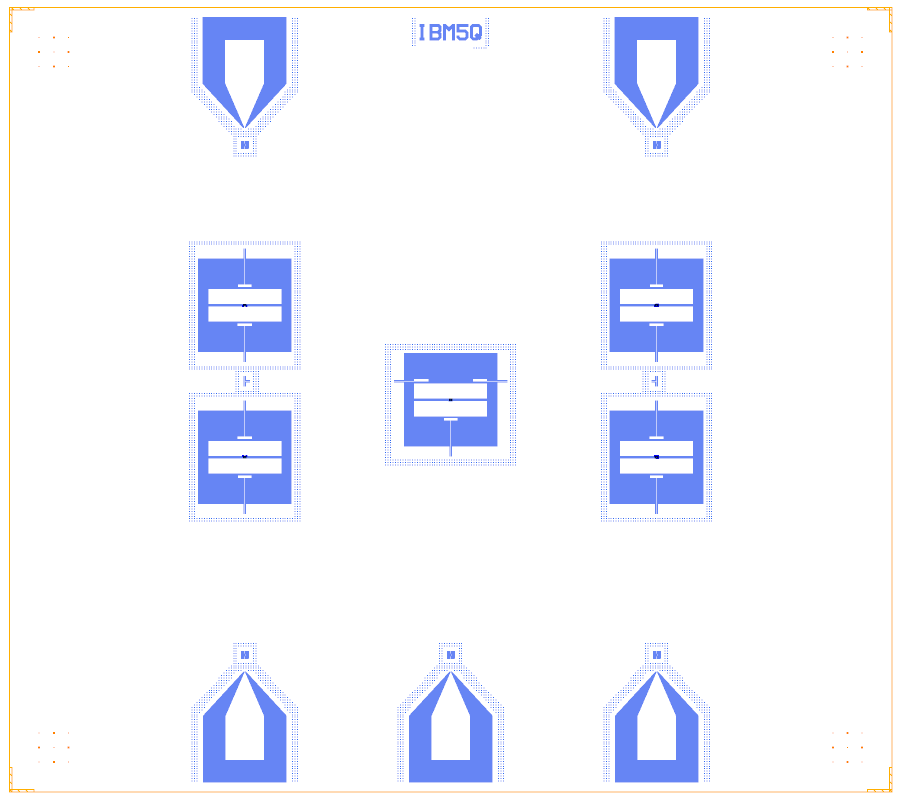

In [8]:
tee = {bus: d.add(f"T{bus[-1]}", "metal:LineTee", at=(XC + sx * DX, YT), rot=90 if sx < 0 else -90)
       for bus, sx in (("BusA", -1), ("BusB", 1))}
fc = {n: d.add(f"C_{n}", "FingerCapacitorSquare", at=(X[n], Y_PAD[n] + (-250 if n in UP else 250)), rot=90)
      for n in X}
snap(d, OUT / "ibm_bowtie_5q_components.png", size=(900, 800), width=320);

## 5 · Routes: buses and readouts

- **Buses:** a λ/2 meander from Q2's bus pad to the tee's `second_end` (lengths set for 7.0 / 6.6 GHz with the LOM),
  and two short stubs from the tee to the outer qubits' bus pads. Both λ/2 ends sit at voltage antinodes.
- **Readouts:** a λ/2 meander from each qubit's readout pad to its finger capacitor (lengths set for IBM's readout
  frequencies), then a short 50 Ω line to the pad.

In [9]:
L_BUS = {"BusA": 8190, "BusB": 8750}             # λ/2 bus lengths Q2 → tee (set for F_BUS with the LOM)
L_RO = {"Q0": 9420, "Q1": 9494, "Q2": 9562, "Q3": 9348, "Q4": 9420}                   # λ/2 readouts (F_RO)
for bus, sx, pin, (top, bot) in (("BusA", -1, "bw", ("Q0", "Q1")), ("BusB", 1, "be", ("Q3", "Q4"))):
    t = tee[bus]
    xm = XC + sx * (DX - 475 - 50)               # meander between the outer pockets and Q2's pocket
    d.route(bus, q["Q2"][pin], t.second_end, meander=L_BUS[bus], r=50, nodes=[(xm, YT)])
    d.route(f"{bus}_{top}", t.prime_end if sx < 0 else t.prime_start, q[top].bus, r=50)
    d.route(f"{bus}_{bot}", t.prime_start if sx < 0 else t.prime_end, q[bot].bus, r=50)
for name, qq in q.items():
    up = name in UP
    d.route(f"R_{name}", qq.ro, fc[name].a if up else fc[name].b, meander=L_RO[name], r=50)
    d.route(f"L_{name}", fc[name].b if up else fc[name].a, bp[name].a, r=50)
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

{'BusA': 8190.0, 'BusA_Q0': 150.0, 'BusA_Q1': 150.0, 'BusB': 8750.0, 'BusB_Q3': 150.0, 'BusB_Q4': 150.0, 'R_Q0': 9420.0, 'L_Q0': 138.5, 'R_Q1': 9494.0, 'L_Q1': 138.5, 'R_Q2': 9562.0, 'L_Q2': 138.5, 'R_Q3': 9348.0, 'L_Q3': 138.5, 'R_Q4': 9420.0, 'L_Q4': 138.5}


## 6 · PDK placement, targets and FEM groups

`center_in_die(d)` measures the bounding box of all instances and routes and shifts them to centre it; Q2 sits at the
die centre and the layout is mirror-symmetric, so it returns (0, 0).

Targets: IBM's f_q and α per qubit, the readout and bus frequencies. FEM boxes: each triangle (three qubits, the bus,
tee and stubs: the C-matrix gives every bus pad's C_g) and Q2 with its readout and finger capacitor. The layout is
complete and is saved.

In [10]:
print("centring shift (µm):", center_in_die(d))
d.targets(**{n: {"f_q_GHz": F_Q[n], "alpha_MHz": ALPHA[n]} for n in F_Q},
          **{f"R_{n}": {"f_GHz": F_RO[n]} for n in F_Q}, **{b: {"f_GHz": f} for b, f in F_BUS.items()})
d.sim_group("triangle_A", ["Q0", "Q1", "Q2", "BusA", "TA", "BusA_Q0", "BusA_Q1"], margin_um=100,
            analyses=["q3d_cmatrix"])
d.sim_group("triangle_B", ["Q2", "Q3", "Q4", "BusB", "TB", "BusB_Q3", "BusB_Q4"], margin_um=100,
            analyses=["q3d_cmatrix"])
d.sim_group("Q2_read", ["Q2", "R_Q2", "C_Q2"], margin_um=100, analyses=["q3d_cmatrix", "eigenmode_epr"])
DESIGN = d.save(OUT / "ibm_bowtie_5q.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)
<Designer ibm_bowtie_5q: 17 instances, 16 routes, live=False> → examples\designs\ibm\ibm_bowtie_5q.json


## 7 · DRC

- **errors:** none expected;
- **warnings:** `dangling_port` on the `squid_a` / `squid_b` junction attachment points of the five pockets (the cell
  draws the trilayer junction across the pad gap itself);
- **PDK design warnings:** none expected (every R_n is in the window, every f_q target in 4–8 GHz, every pad at 100 µm).

This run: **0 errors · 10 warnings (`dangling_port`) · 0 PDK design warnings**; drawn R_n 40.9–44.1 kΩ.

In [11]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 10 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 10 | Q0.squid_a is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 5 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`TransmonPocket6` → two floating pads (`island1` / `island2`) with the trilayer junction between them (the drawn
L_J / C_J), a node per connection pad. Each bus (Q2's pad → tee → two stubs) is one node: the λ/2 `TLres` of the
meander joins Q2's bus pad, the tee and both outer pads (the stubs are wires; their 2 × 150 µm are not in the
resonator length: the eigenmode job holds them). Each readout is a λ/2 between the qubit's pad and the finger
capacitor, whose other side is the 50 Ω pad.

In [12]:
lb = d.lom()
show_netlist(lb)

**23 nodes · 80 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `C_Q0.b` | `P_Q0.pad`, `C_Q0.b` |
| `C_Q1.a` | `P_Q1.pad`, `C_Q1.a` |
| `C_Q2.a` | `P_Q2.pad`, `C_Q2.a` |
| `C_Q3.b` | `P_Q3.pad`, `C_Q3.b` |
| `C_Q4.a` | `P_Q4.pad`, `C_Q4.a` |
| `Q0.island1` | `Q0.island1` |
| `Q0.island2` | `Q0.island2` |
| `Q0.bus` | `Q0.bus`, `Q1.bus`, `Q2.bw`, `TA.t` |
| `Q0.ro` | `Q0.ro`, `C_Q0.a` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.ro` | `Q1.ro`, `C_Q1.b` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.be` | `Q2.be`, `Q3.bus`, `Q4.bus`, `TB.t` |
| `Q2.ro` | `Q2.ro`, `C_Q2.b` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.ro` | `Q3.ro`, `C_Q3.a` |
| `Q4.island1` | `Q4.island1` |
| `Q4.island2` | `Q4.island2` |
| `Q4.ro` | `Q4.ro`, `C_Q4.b` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P_Q0` | R | `C_Q0.b` – `gnd` | 50 Ω |
| `Port_P_Q1` | R | `C_Q1.a` – `gnd` | 50 Ω |
| `Port_P_Q2` | R | `C_Q2.a` – `gnd` | 50 Ω |
| `Port_P_Q3` | R | `C_Q3.b` – `gnd` | 50 Ω |
| `Port_P_Q4` | R | `C_Q4.a` – `gnd` | 50 Ω |
| `C_Q0_1` | C | `Q0.island1` – `gnd` | 82.8 fF |
| `C_Q0_2` | C | `Q0.island2` – `gnd` | 82.8 fF |
| `C_Q0_12` | C | `Q0.island1` – `Q0.island2` | 75.5 fF |
| `J_Q0` | JJ | `Q0.island1` – `Q0.island2` | Lj 6.12 nH, Cj 16.5 fF |
| `Cg_Q0_bus` | C | `Q0.island2` – `Q0.bus` | 16.9 fF |
| `Cf_Q0_bus` | C | `Q0.island1` – `Q0.bus` | 1.8 fF |
| `Cc_Q0_bus` | C | `Q0.bus` – `gnd` | 31 fF |
| `Cg_Q0_ro` | C | `Q0.island1` – `Q0.ro` | 15.8 fF |
| `Cf_Q0_ro` | C | `Q0.island2` – `Q0.ro` | 1.7 fF |
| `Cc_Q0_ro` | C | `Q0.ro` – `gnd` | 30.5 fF |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 82.8 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 82.8 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 75.5 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 6.24 nH, Cj 16.2 fF |
| `Cg_Q1_bus` | C | `Q1.island1` – `Q0.bus` | 16.9 fF |
| `Cf_Q1_bus` | C | `Q1.island2` – `Q0.bus` | 1.8 fF |
| `Cc_Q1_bus` | C | `Q0.bus` – `gnd` | 31 fF |
| `Cg_Q1_ro` | C | `Q1.island2` – `Q1.ro` | 15.8 fF |
| `Cf_Q1_ro` | C | `Q1.island1` – `Q1.ro` | 1.7 fF |
| `Cc_Q1_ro` | C | `Q1.ro` – `gnd` | 30.5 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 82.8 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 82.8 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 75.5 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 6.6 nH, Cj 15.3 fF |
| `Cg_Q2_bw` | C | `Q2.island1` – `Q0.bus` | 16.9 fF |
| `Cf_Q2_bw` | C | `Q2.island2` – `Q0.bus` | 1.8 fF |
| `Cc_Q2_bw` | C | `Q0.bus` – `gnd` | 31 fF |
| `Cg_Q2_be` | C | `Q2.island1` – `Q2.be` | 16.9 fF |
| `Cf_Q2_be` | C | `Q2.island2` – `Q2.be` | 1.8 fF |
| `Cc_Q2_be` | C | `Q2.be` – `gnd` | 31 fF |
| `Cg_Q2_ro` | C | `Q2.island2` – `Q2.ro` | 15.8 fF |
| `Cf_Q2_ro` | C | `Q2.island1` – `Q2.ro` | 1.7 fF |
| `Cc_Q2_ro` | C | `Q2.ro` – `gnd` | 30.5 fF |
| `C_Q3_1` | C | `Q3.island1` – `gnd` | 82.8 fF |
| `C_Q3_2` | C | `Q3.island2` – `gnd` | 82.8 fF |
| `C_Q3_12` | C | `Q3.island1` – `Q3.island2` | 75.5 fF |
| `J_Q3` | JJ | `Q3.island1` – `Q3.island2` | Lj 6.12 nH, Cj 16.5 fF |
| `Cg_Q3_bus` | C | `Q3.island2` – `Q2.be` | 16.9 fF |
| `Cf_Q3_bus` | C | `Q3.island1` – `Q2.be` | 1.8 fF |
| `Cc_Q3_bus` | C | `Q2.be` – `gnd` | 31 fF |
| `Cg_Q3_ro` | C | `Q3.island1` – `Q3.ro` | 15.8 fF |
| `Cf_Q3_ro` | C | `Q3.island2` – `Q3.ro` | 1.7 fF |
| `Cc_Q3_ro` | C | `Q3.ro` – `gnd` | 30.5 fF |
| `C_Q4_1` | C | `Q4.island1` – `gnd` | 82.8 fF |
| `C_Q4_2` | C | `Q4.island2` – `gnd` | 82.8 fF |
| `C_Q4_12` | C | `Q4.island1` – `Q4.island2` | 75.5 fF |
| `J_Q4` | JJ | `Q4.island1` – `Q4.island2` | Lj 6.6 nH, Cj 15.3 fF |
| `Cg_Q4_bus` | C | `Q4.island1` – `Q2.be` | 16.9 fF |
| `Cf_Q4_bus` | C | `Q4.island2` – `Q2.be` | 1.8 fF |
| `Cc_Q4_bus` | C | `Q2.be` – `gnd` | 31 fF |
| `Cg_Q4_ro` | C | `Q4.island2` – `Q4.ro` | 15.8 fF |
| `Cf_Q4_ro` | C | `Q4.island1` – `Q4.ro` | 1.7 fF |
| `Cc_Q4_ro` | C | `Q4.ro` – `gnd` | 30.5 fF |
| `C_C_Q0` | C | `Q0.ro` – `C_Q0.b` | 7.18 fF |
| `C_C_Q0_a` | C | `Q0.ro` – `gnd` | 3.5 fF |
| `C_C_Q0_b` | C | `C_Q0.b` – `gnd` | 3.5 fF |
| `C_C_Q1` | C | `C_Q1.a` – `Q1.ro` | 7.18 fF |
| `C_C_Q1_a` | C | `C_Q1.a` – `gnd` | 3.5 fF |
| `C_C_Q1_b` | C | `Q1.ro` – `gnd` | 3.5 fF |
| `C_C_Q2` | C | `C_Q2.a` – `Q2.ro` | 7.18 fF |
| `C_C_Q2_a` | C | `C_Q2.a` – `gnd` | 3.5 fF |
| `C_C_Q2_b` | C | `Q2.ro` – `gnd` | 3.5 fF |
| `C_C_Q3` | C | `Q3.ro` – `C_Q3.b` | 7.18 fF |
| `C_C_Q3_a` | C | `Q3.ro` – `gnd` | 3.5 fF |
| `C_C_Q3_b` | C | `C_Q3.b` – `gnd` | 3.5 fF |
| `C_C_Q4` | C | `C_Q4.a` – `Q4.ro` | 7.18 fF |
| `C_C_Q4_a` | C | `C_Q4.a` – `gnd` | 3.5 fF |
| `C_C_Q4_b` | C | `Q4.ro` – `gnd` | 3.5 fF |
| `BusA` | TLres | `Q0.bus` – `gnd` | lambda/2, 8190 µm, 7.694 GHz |
| `BusB` | TLres | `Q2.be` – `gnd` | lambda/2, 8750 µm, 7.202 GHz |
| `R_Q0` | TLres | `Q0.ro` – `gnd` | lambda/2, 9420 µm, 6.690 GHz |
| `R_Q1` | TLres | `Q1.ro` – `gnd` | lambda/2, 9494 µm, 6.638 GHz |
| `R_Q2` | TLres | `Q2.ro` – `gnd` | lambda/2, 9562 µm, 6.590 GHz |
| `R_Q3` | TLres | `Q3.ro` – `gnd` | lambda/2, 9348 µm, 6.741 GHz |
| `R_Q4` | TLres | `Q4.ro` – `gnd` | lambda/2, 9420 µm, 6.690 GHz |

**Unconnected ports:** none

## 9 · LOM simulation

**(a) Qubit + readout pairs** (QuTiP dressed; targets in brackets). The L_J of step 4 were solved with these groups so
that f_q lands on IBM's frequencies.

This run: f_q 5.028–5.2685 GHz, within 23 MHz of IBM's; α −143 … −147 MHz (IBM −330 … −376 MHz, see step 13);
f_r 6.337–6.477 GHz, 1.6 % below IBM's measurement LOs: the λ/2 lengths were set before the Nb film's kinetic
inductance (PDK `kinetic`) entered the LOM, which makes every line ≈ 1.6 % slower (flagged, not retuned); κ
0.87–0.93 MHz; χ −0.69 … −0.89 MHz (ibmqx4's table gives 0.41–0.51 MHz).

In [13]:
read = {f"{n}+R": [n, f"R_{n}", f"C_{n}", f"L_{n}", f"P_{n}"] for n in F_Q}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, d.data["targets"])))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q0+R | Q0 | 5.2684 (5.2823) | -145.1 (-330.8) | R_Q0 | 6.429 (6.5304) | 0.908 | -0.888 |
| Q1+R | Q1 | 5.2244 (5.2475) | -145.5 (-330.4) | R_Q1 | 6.3808 (6.4817) | 0.888 | -0.878 |
| Q2+R | Q2 | 5.028 (5.0334) | -143.2 (-376.1) | R_Q2 | 6.3367 (6.4365) | 0.871 | -0.737 |
| Q3+R | Q3 | 5.2685 (5.292) | -145.2 (-329.7) | R_Q3 | 6.4765 (6.5789) | 0.929 | -0.841 |
| Q4+R | Q4 | 5.0893 (5.0785) | -147 (-333.1) | R_Q4 | 6.4285 (6.5301) | 0.909 | -0.687 |

**(b) The two buses and the exchange couplings.** Each triangle (three qubits, the bus, tee and stubs) is simulated as
one circuit: the bus mode and the qubits' dressed frequencies. J of each coupled pair is the half-splitting at the
avoided crossing (the second qubit's L_J is swept through the first's frequency, `exchange_coupling`), next to IBM's
Hamiltonian value; ZZ is the static ZZ at the design frequencies. J of the pairs through Q2 is taken on the pair with
its bus (the third qubit left out: ≈ 10 s per pair; its pad shifts the bus by a few tens of MHz), the outer pairs
Q0–Q1 and Q3–Q4 on the whole triangle (both must keep Q2's end of the bus: ≈ 2 min each). The two outer qubits of a
triangle share the tee, so in the LOM all three couple to the same bus node.

This run: the bus modes at 6.911 (A) and 6.511 GHz (B), 1.3 % below 7.0 / 6.6 GHz (the same kinetic inductance);
J Q0–Q1 1.80 (IBM 1.91), Q0–Q2 1.61 (1.82), Q1–Q2 1.55 (1.24), Q2–Q3 1.56 (1.82), Q2–Q4 1.57 (1.81) and Q3–Q4
3.78 MHz (2.01): the outer pair Q3–Q4 is detuned by only 0.18 GHz, so its avoided-crossing estimate runs high;
static ZZ −173 … +76 kHz.

In [14]:
tri = {"A": ["Q0", "Q1", "Q2", "BusA", "TA", "BusA_Q0", "BusA_Q1"],
       "B": ["Q2", "Q3", "Q4", "BusB", "TB", "BusB_Q3", "BusB_Q4"]}
buses = simulate_groups(d, {f"triangle {k}": sel for k, sel in tri.items()}, max_modes=4)
for g, res in buses.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown(f"Bus targets: {F_BUS} GHz"))
PAIRS = {"Q0-Q1": tri["A"], "Q0-Q2": ["Q0", "Q2", "BusA", "TA", "BusA_Q0"],
         "Q1-Q2": ["Q1", "Q2", "BusA", "TA", "BusA_Q1"], "Q2-Q3": ["Q2", "Q3", "BusB", "TB", "BusB_Q3"],
         "Q2-Q4": ["Q2", "Q4", "BusB", "TB", "BusB_Q4"], "Q3-Q4": tri["B"]}
J = {p: exchange_coupling(d, sel, *p.split("-")) for p, sel in PAIRS.items()}
display(Markdown(exchange_md(J, J_SRC)))

**triangle A, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q2 | qubit | 5.1700 | 0 | 134.6 | J_Q2 1.00 |
| Q1 | qubit | 5.3641 | 0 | 135.9 | J_Q1 1.00 |
| Q0 | qubit | 5.4079 | 0 | 135.7 | J_Q0 1.00 |
| BusA | resonator | 6.9110 | 0 | 0.0 | BusA 0.99 |

**triangle B, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q2 | qubit | 5.1696 | 0 | 134.0 | J_Q2 1.00 |
| Q4 | qubit | 5.2295 | 0 | 137.1 | J_Q4 1.00 |
| Q3 | qubit | 5.4071 | 0 | 135.9 | J_Q3 1.00 |
| BusB | resonator | 6.5112 | 0 | 0.0 | BusB 0.99 |

Bus targets: {'BusA': 7.0, 'BusB': 6.6} GHz

| pair | f_a (GHz) | f_b (GHz) | J (MHz) | target J (MHz) | ZZ (kHz) |
|---|---|---|---|---|---|
| Q0-Q1 | 5.2679 | 5.2238 | 1.8 | 1.91 | 76 |
| Q0-Q2 | 5.2675 | 5.0315 | 1.61 | 1.82 | -30 |
| Q1-Q2 | 5.2235 | 5.0315 | 1.55 | 1.24 | -63.1 |
| Q2-Q3 | 5.0312 | 5.2670 | 1.56 | 1.82 | -45.9 |
| Q2-Q4 | 5.0312 | 5.0879 | 1.57 | 1.81 | 69.6 |
| Q3-Q4 | 5.2675 | 5.0881 | 3.78 | 2.01 | -173 |

## 10 · FEM: send the job

Four jobs: a Q3D C-matrix job per triangle (the bus pads' C_g to both qubit pads, the stubs, the tee) and, for Q2, a
C-matrix and an eigenmode job with its readout and finger capacitor. Simulation exports never carry cheese; exporting
again replaces a job folder, results included.

`RUN_FEM = False` only exports. With `RUN_FEM = True` and AEDT 2024 R1 (or newer) here, `send_fem_jobs` solves each job in
a **new batch, non-graphical AEDT** (`solve_job`); an open AEDT window is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [15]:
RUN_FEM = False                                  # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
jobs = export_sims(DESIGN, ["triangle_A", "triangle_B", "Q2_read"])
jobs_eig = export_sims(DESIGN, ["Q2_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    send_fem_jobs(DESIGN, ["triangle_A", "triangle_B", "Q2_read"], run=True)   # each group's own analyses

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| triangle_A | `build/jobs/ibm_bowtie_5q_triangle_A_q3d_cmatrix` | 1 · junction · `Q0.junction`<br>2 · junction · `Q1.junction`<br>3 · junction · `Q2.junction`<br>4 · waveguide · `Q2.bw`<br>5 · waveguide · `TA.second_end`<br>6 · waveguide · `TA.prime_end`<br>7 · waveguide · `Q0.bus`<br>8 · waveguide · `TA.prime_start`<br>9 · waveguide · `Q1.bus`<br>10 · edge · `BusB`<br>11 · edge · `R_Q0`<br>12 · edge · `R_Q1`<br>13 · edge · `R_Q2` | `Q0.island2`, `Q1.island2`, `Q2.island2`, `Q2.bw`, `TA.second_end`, `TA.prime_end`, `TA.prime_start`, `BusB`, `R_Q0`, `R_Q1`, `R_Q2`, `Q1.island1`, `Q2.island1`, `Q0.island1` |
| triangle_B | `build/jobs/ibm_bowtie_5q_triangle_B_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · junction · `Q3.junction`<br>3 · junction · `Q4.junction`<br>4 · waveguide · `Q2.be`<br>5 · waveguide · `TB.second_end`<br>6 · waveguide · `TB.prime_start`<br>7 · waveguide · `Q3.bus`<br>8 · waveguide · `TB.prime_end`<br>9 · waveguide · `Q4.bus`<br>10 · edge · `BusA`<br>11 · edge · `R_Q2`<br>12 · edge · `R_Q3`<br>13 · edge · `R_Q4` | `Q2.island2`, `Q3.island2`, `Q4.island2`, `Q2.be`, `TB.second_end`, `TB.prime_start`, `TB.prime_end`, `BusA`, `R_Q2`, `R_Q3`, `R_Q4`, `Q4.island1`, `Q2.island1`, `Q3.island1` |
| Q2_read | `build/jobs/ibm_bowtie_5q_Q2_read_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.ro`<br>3 · waveguide · `C_Q2.b`<br>4 · edge · `BusA`<br>5 · edge · `BusB`<br>6 · edge · `L_Q2` | `Q2.island2`, `Q2.ro`, `C_Q2.b`, `BusA`, `BusB`, `L_Q2`, `Q2.island1` |
| Q2_read | `build/jobs/ibm_bowtie_5q_Q2_read_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · edge_lumped · `BusA`<br>3 · edge_lumped · `BusB`<br>4 · edge_lumped · `L_Q2` | `Q2.island2`, `BusA`, `BusB`, `L_Q2`, `Q2.ro`, `Q2.island1` |

## 11 · Bring the results back

With results in `build/jobs/<job>/results/results.json`, `fill(model, design, job)` replaces the LOM capacitance
estimates by net name (each pocket's `island1` / `island2`, the bus pads, the readout pads) and keeps the estimates
beside them; steps 9 (a)–(b) can then be run again on the extracted values. Until a solve has run, the cell says what
would appear.

In [16]:
filled, md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()},
                                         **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(md))

No FEM results yet for triangle_A · q3d, triangle_B · q3d, Q2_read · q3d, Q2_read · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Iterate: change one property and re-simulate

J(Q0–Q2) comes out below IBM's 1.82 MHz. The knob is the bus pad: here Q0's goes from 150 to 120 µm, the other
direction, so J drops further — the LOM shows by how much in ≈ 10 s. This run: J(Q0–Q2) 1.61 → 1.35 MHz, ZZ −30 → −17 kHz. `design_copy` opens a second, non-live Designer
on the saved design; the design file stays as it is.

In [17]:
d2 = design_copy(DESIGN)
d2["Q0"].set(connection_pads={**place["Q0"][2], **cpad("bus", 0, -1, 120)})
J2 = {"Q0-Q2 (bus pad 150 µm)": J["Q0-Q2"],
      "Q0-Q2 (bus pad 120 µm)": exchange_coupling(d2, PAIRS["Q0-Q2"], "Q0", "Q2")}
display(Markdown(exchange_md(J2, {k: J_SRC["Q0-Q2"] for k in J2})))

| pair | f_a (GHz) | f_b (GHz) | J (MHz) | target J (MHz) | ZZ (kHz) |
|---|---|---|---|---|---|
| Q0-Q2 (bus pad 150 µm) | 5.2675 | 5.0315 | 1.61 | 1.82 | -30 |
| Q0-Q2 (bus pad 120 µm) | 5.2842 | 5.0315 | 1.35 | 1.82 | -16.9 |

## 13 · the two alternatives for α

With PDK junctions (R_n 40–50 kΩ, so L_J ≤ 7.5 nH and E_J/h ≥ 22 GHz), a 5 GHz pocket needs a large C_Σ and its α is
only ≈ −145 MHz against IBM's −330 MHz. Both alternatives are shown; both are LOM what-ifs on a
copy of the design (the saved design is unchanged), and each is compared on the same footing: every qubit with its
readout, and both triangles at once for the static ZZ of every pair (one simulation per triangle).

A transmon has f_q ≈ √(8 E_J E_C) − E_C and α ≈ −E_C (a little more), with E_C/h = e²/2hC_Σ and
E_J/h = 163.46 GHz·nH / L_J. `resize` (below) infers E_C from a simulated (L_J, f_q) and sets the L_J that puts f_q
on the target; two passes absorb the junction's own C_J.

In [18]:
EJ_LJ = 163.46                                   # E_J/h (GHz) × L_J (nH) = (Φ0/2π)²/h


def ec_from(f_GHz, lj_nH):
    """E_C/h (GHz) of a transmon from its f_q and L_J: the small root of f = √(8 E_J E_C) − E_C."""
    s = math.sqrt(8 * EJ_LJ / lj_nH)
    return ((s - math.sqrt(s * s - 4 * f_GHz)) / 2) ** 2


def resize(dd, f_target, groups, cell="metal:TransmonPocket6", passes=2):
    """LOM what-if: re-draw each qubit's trilayer junction in ``dd`` for ``f_target`` (GHz)."""
    for _ in range(passes):
        res = simulate_groups(dd, {q_: groups[q_] for q_ in f_target})
        for q_, ft in f_target.items():
            ec = ec_from(res[q_].params[f"{q_}.f_q_GHz"], dd.data["instances"][q_]["junction"]["Lj_nH"])
            params, jj = trilayer_junction(cell, lj_nH=EJ_LJ * 8 * ec / (ft + ec) ** 2)
            dd[q_].set(junction=jj, **params)
    return simulate_groups(dd, {q_: groups[q_] for q_ in f_target})


def plan_md(dd, res, window):
    """Junction, f_q and α per qubit against IBM's, with the R_n window flag."""
    rows = [f"| qubit | L_J (nH) | R_n (kΩ) | R_n in {window[0]}–{window[1]} kΩ | f_q (GHz) [IBM] | α (MHz) [IBM] |",
            "|---|---|---|---|---|---|"]
    for g, r in res.items():
        q_ = g.split("+")[0]
        lj = dd.data["instances"][q_]["junction"]["Lj_nH"]
        rn = rn_from_lj(lj) / 1e3
        rows.append(f"| {q_} | {lj:.2f} | {rn:.1f} | {'yes' if window[0] <= rn <= window[1] else 'no'} | "
                    f"{r.params[f'{q_}.f_q_GHz']:.4f} [{F_Q[q_]}] | {r.params[f'{q_}.alpha_MHz']:.0f} [{ALPHA[q_]}] |")
    return "\n".join(rows)


def zz_tri(dd):
    """Static ZZ of every pair, both triangles simulated whole (QuTiP dressed)."""
    return simulate_groups(dd, {f"triangle {k}": sel for k, sel in tri.items()}, max_modes=4)


base_zz = zz_tri(d)
display(Markdown("**The design (PDK window, C_Σ ≈ 140 fF):**\n\n" + zz_md(base_zz)))

**The design (PDK window, C_Σ ≈ 140 fF):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| triangle A | Q1-Q2 | -74.22 | yes | no |
| triangle A | Q0-Q2 | -35.81 | yes | no |
| triangle A | Q0-Q1 | 83.92 | yes | no |
| triangle B | Q2-Q4 | 83.34 | yes | no |
| triangle B | Q2-Q3 | -57.46 | yes | no |
| triangle B | Q3-Q4 | -195.4 | yes | no |

**(A) A wider R_n window, 30–80 kΩ.** A larger L_J (up to 12 nH at 80 kΩ) lets a smaller pocket reach 5 GHz, and a
smaller pocket has the larger E_C IBM uses. The pads shrink from 750 × 160 to 380 × 100 µm (C_Σ ≈ 77 fF in the LOM,
E_C ≈ 0.25 GHz), and every junction is re-sized for IBM's f_q. This run: L_J 12.0–13.0 nH, R_n 80.4–86.5 kΩ:
on the PDK finger grid the drawn junctions land just above even the wider window (the table's "no"); α −316 …
−339 MHz, at IBM's; f_q within 1.3 % of IBM's; χ −3.2 … −4.4 MHz (the bus and readout pads are kept, the pocket
is smaller). In triangle A the three qubits come within 0.3 GHz of each other and hybridise (no ZZ), in triangle B
the static ZZ is 132–342 kHz.

In [19]:
dA = design_copy(DESIGN, "_wide_rn")
for n in F_Q:
    dA[n].set(pad_width=380, pad_height=100)
resA = resize(dA, F_Q, {n: read[f"{n}+R"] for n in F_Q})
display(Markdown(plan_md(dA, resA, (30, 80))))
display(Markdown(groups_md(resA, d.data["targets"])))
display(Markdown(zz_md(zz_tri(dA))))

| qubit | L_J (nH) | R_n (kΩ) | R_n in 30–80 kΩ | f_q (GHz) [IBM] | α (MHz) [IBM] |
|---|---|---|---|---|---|
| Q0 | 12.03 | 80.4 | no | 5.3139 [5.2823] | -333 [-330.8] |
| Q1 | 12.03 | 80.4 | no | 5.3136 [5.2475] | -332 [-330.4] |
| Q2 | 12.47 | 83.3 | no | 5.0929 [5.0334] | -316 [-376.1] |
| Q3 | 12.03 | 80.4 | no | 5.3141 [5.292] | -333 [-329.7] |
| Q4 | 12.95 | 86.5 | no | 5.1312 [5.0785] | -339 [-333.1] |

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q0 | Q0 | 5.3139 (5.2823) | -332.5 (-330.8) | R_Q0 | 6.3954 (6.5304) | 0.882 | -4.11 |
| Q1 | Q1 | 5.3136 (5.2475) | -332.3 (-330.4) | R_Q1 | 6.348 (6.4817) | 0.862 | -4.36 |
| Q2 | Q2 | 5.0929 (5.0334) | -316.3 (-376.1) | R_Q2 | 6.3036 (6.4365) | 0.847 | -3.76 |
| Q3 | Q3 | 5.3141 (5.292) | -332.7 (-329.7) | R_Q3 | 6.4422 (6.5789) | 0.903 | -3.9 |
| Q4 | Q4 | 5.1312 (5.0785) | -339.1 (-333.1) | R_Q4 | 6.3942 (6.5301) | 0.885 | -3.18 |

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| triangle A | Q0-Q2 | – | yes | yes |
| triangle A | Q1-Q2 | – | yes | yes |
| triangle A | Q0-Q1 | – | yes | yes |
| triangle B | Q2-Q4 | 235.9 | yes | no |
| triangle B | Q2-Q3 | 341.7 | yes | no |
| triangle B | Q3-Q4 | 131.9 | yes | no |

**(B) A larger C_Σ inside the PDK window.** The pocket grows (pads 1000 × 200 µm in a 1250 × 1150 µm pocket, C_Σ
≈ 190 fF) with the design's junctions (R_n 41–44 kΩ, in the window). A larger C_Σ lowers E_C: f_q falls to 4.37–4.57 GHz
and α to −107 … −109 MHz (this run; χ ≈ −0.2 MHz, ZZ −16 … +18 kHz), so the collision band |Δ| ≈ |α| moves to smaller detunings. It does not bring IBM's α back; it
trades f_q and |α| for charge-noise insensitivity.

In [20]:
dB = design_copy(DESIGN, "_big_c")
for n in F_Q:
    dB[n].set(pad_width=1000, pad_height=200, pocket_width=1250, pocket_height=1150)
resB = simulate_groups(dB, {n: read[f"{n}+R"] for n in F_Q})
display(Markdown(plan_md(dB, resB, (40, 50))))
display(Markdown(groups_md(resB, d.data["targets"])))
display(Markdown(zz_md(zz_tri(dB))))

| qubit | L_J (nH) | R_n (kΩ) | R_n in 40–50 kΩ | f_q (GHz) [IBM] | α (MHz) [IBM] |
|---|---|---|---|---|---|
| Q0 | 6.12 | 40.9 | yes | 4.5746 [5.2823] | -108 [-330.8] |
| Q1 | 6.24 | 41.7 | yes | 4.5354 [5.2475] | -108 [-330.4] |
| Q2 | 6.60 | 44.1 | yes | 4.3748 [5.0334] | -107 [-376.1] |
| Q3 | 6.12 | 40.9 | yes | 4.5746 [5.292] | -108 [-329.7] |
| Q4 | 6.60 | 44.1 | yes | 4.4149 [5.0785] | -109 [-333.1] |

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q0 | Q0 | 4.5746 (5.2823) | -108 (-330.8) | R_Q0 | 6.4221 (6.5304) | 0.907 | -0.202 |
| Q1 | Q1 | 4.5354 (5.2475) | -108.2 (-330.4) | R_Q1 | 6.374 (6.4817) | 0.887 | -0.2 |
| Q2 | Q2 | 4.3748 (5.0334) | -106.9 (-376.1) | R_Q2 | 6.3303 (6.4365) | 0.869 | -0.185 |
| Q3 | Q3 | 4.5746 (5.292) | -108 (-329.7) | R_Q3 | 6.4696 (6.5789) | 0.927 | -0.197 |
| Q4 | Q4 | 4.4149 (5.0785) | -109 (-333.1) | R_Q4 | 6.422 (6.5301) | 0.907 | -0.174 |

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| triangle A | Q1-Q2 | -10.22 | yes | no |
| triangle A | Q0-Q2 | -5.129 | yes | no |
| triangle A | Q0-Q1 | 17.72 | yes | no |
| triangle B | Q2-Q4 | 15.79 | yes | no |
| triangle B | Q2-Q3 | -7.254 | yes | no |
| triangle B | Q3-Q4 | -15.73 | yes | no |

**Reading the two.** (A) is the only one that brings α near IBM's, at the price of junctions outside today's PDK
window (R_n 80–87 kΩ, smaller fingers). (B) stays inside the window but moves every qubit down and |α| further away
from IBM's. Neither is applied to the saved design: the rebuild keeps the PDK junctions and flags the α difference.

## 14 · Build and export

- **Design file:** `examples/designs/ibm/ibm_bowtie_5q.json` (step 6); `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (the PDK band: no original cheese exists; this run: 11 106 holes).
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a
  FEM export (this chip has none); cheese never.
- **The same from the command line:** `qcc build examples/designs/ibm/ibm_bowtie_5q.json`, `qcc design drc …`,
  `qcc mask …`, `qcc sim build … -g triangle_A -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [21]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 11112 |
| 2/0 | JJ_STRAIGHT | 5 |
| 3/0 | M3 | 11112 |
| 4/0 | JJ_BENT | 5 |
| 50/0 | HSQ | 10 |
| 51/0 | SPACER_1 | 10 |
| 52/0 | SPACER_2 | 10 |
| 53/0 | SPACER_3 | 10 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 11106 holes on the mask.

→ `build/ibm_bowtie_5q_fab.oas`

## 15 · Snapshots

The full die (PDK frame, QCT device ID): the bowtie, Q2 in the middle, the two meandered buses out to the tees between
Q0/Q1 and Q3/Q4, five λ/2 readouts to finger capacitors and pads. Then the left triangle, Q2's trilayer junction
across the 20 µm pad gap, a readout's finger capacitor and pad, and the fab mask round Q2 (the PDK band's
5 µm holes along the 3/0 keep-outs, on 1/0 and 3/0, the junction layers).

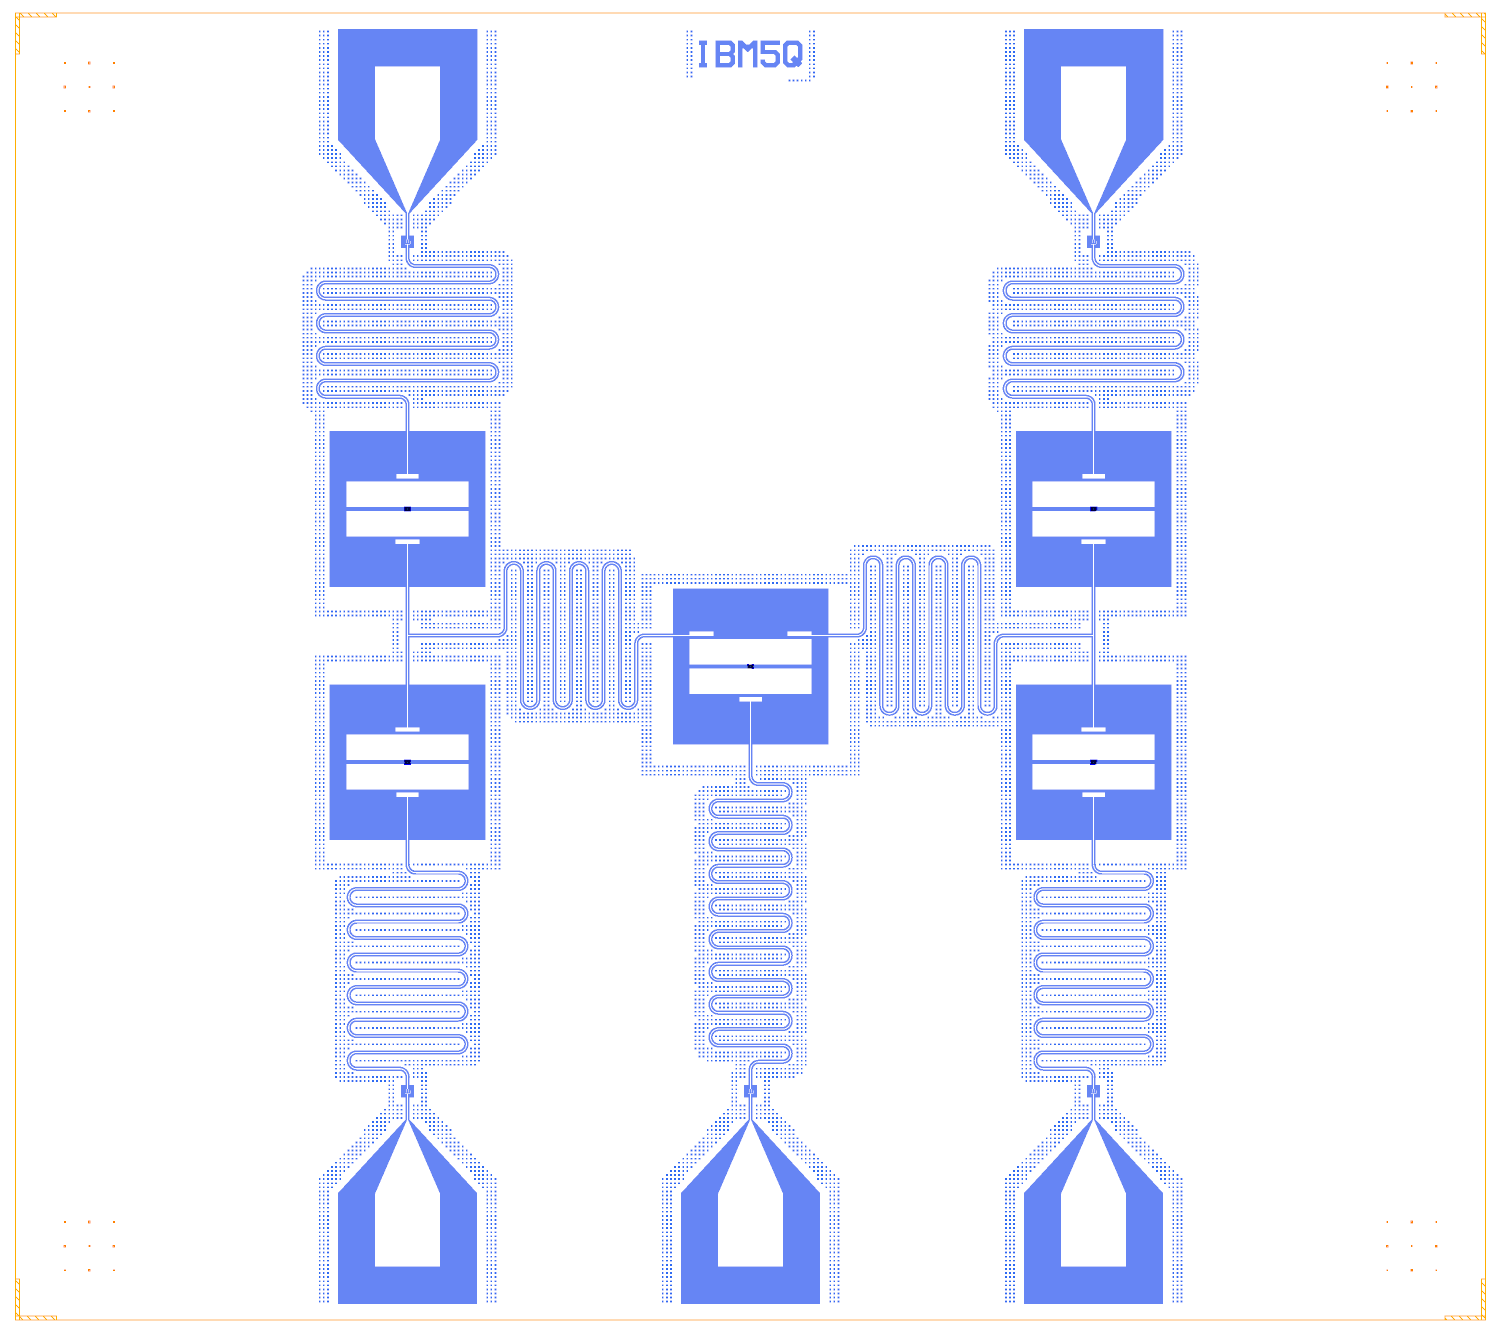

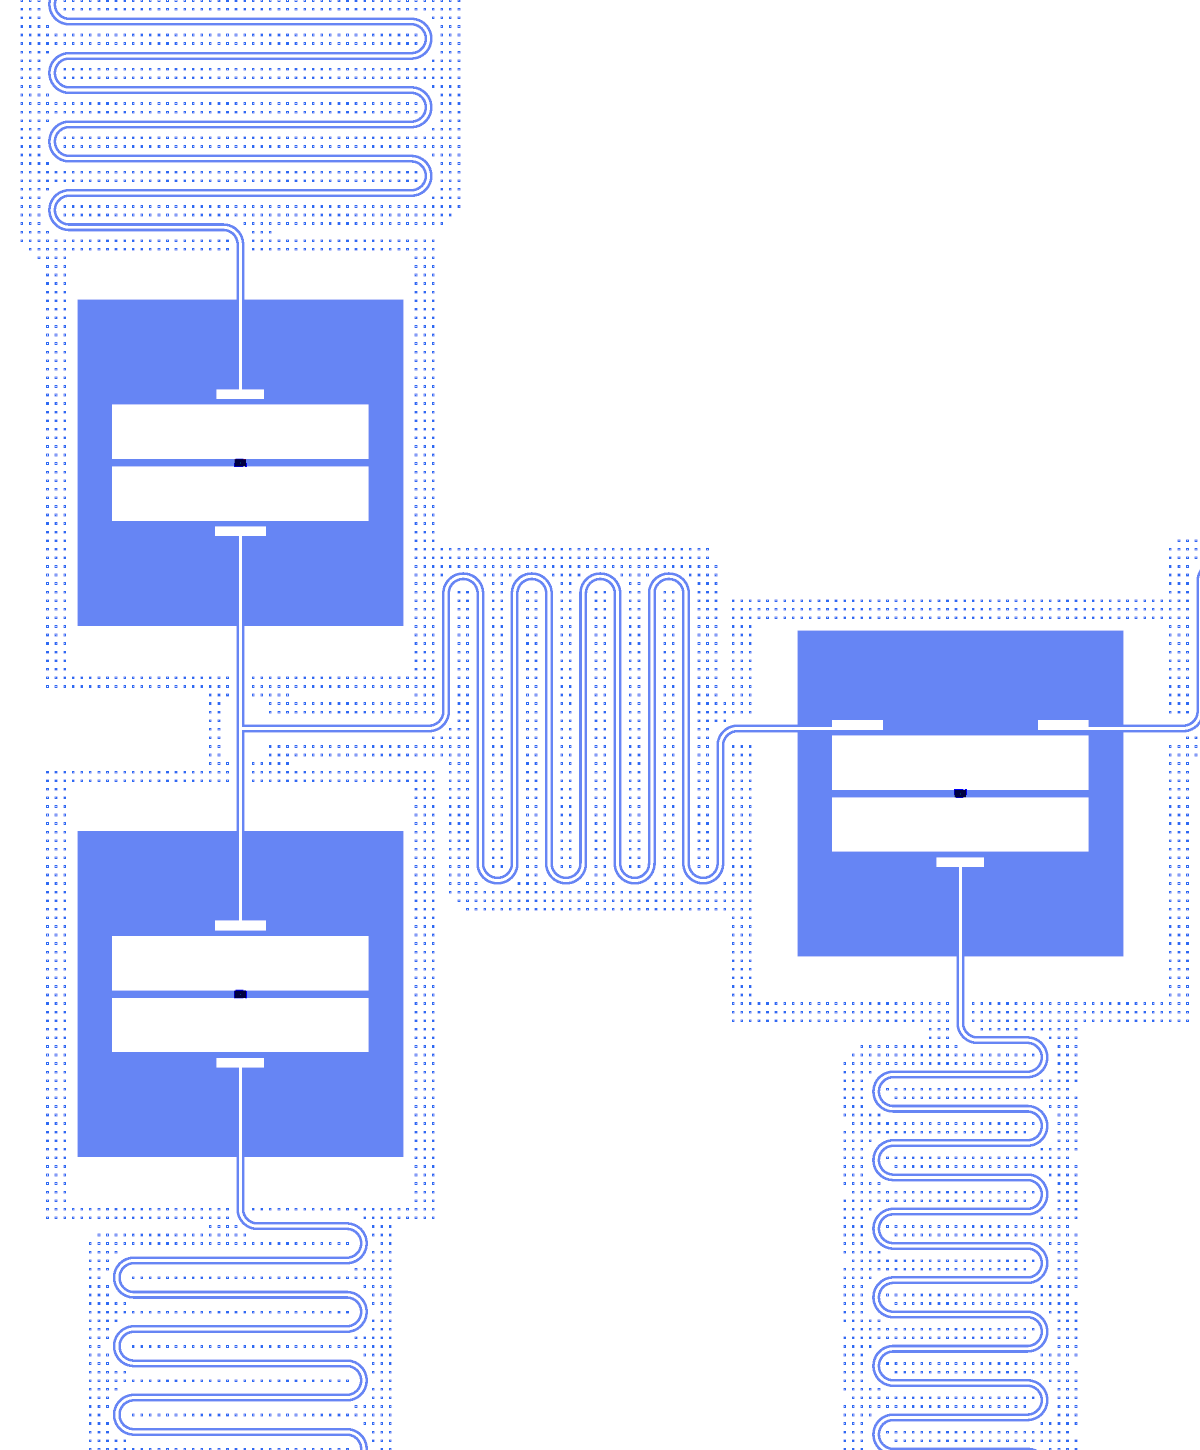

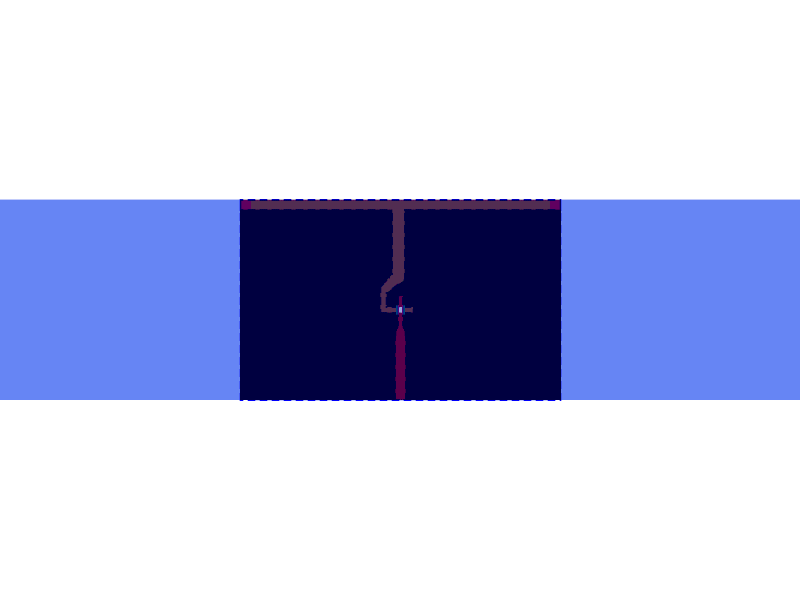

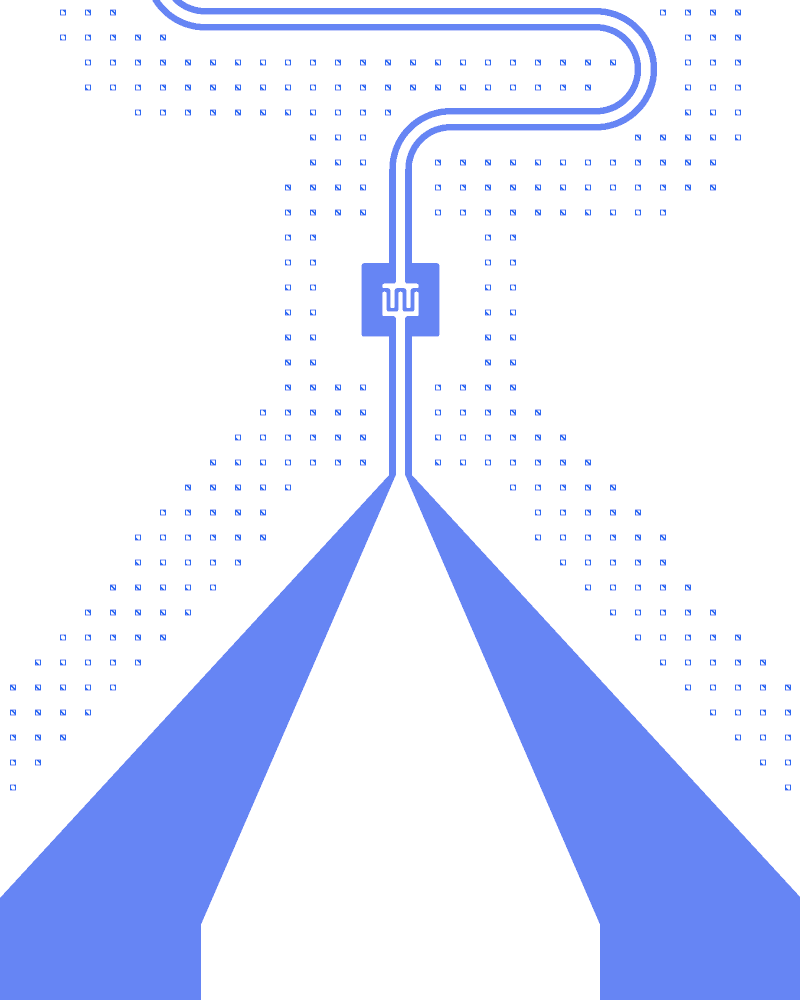

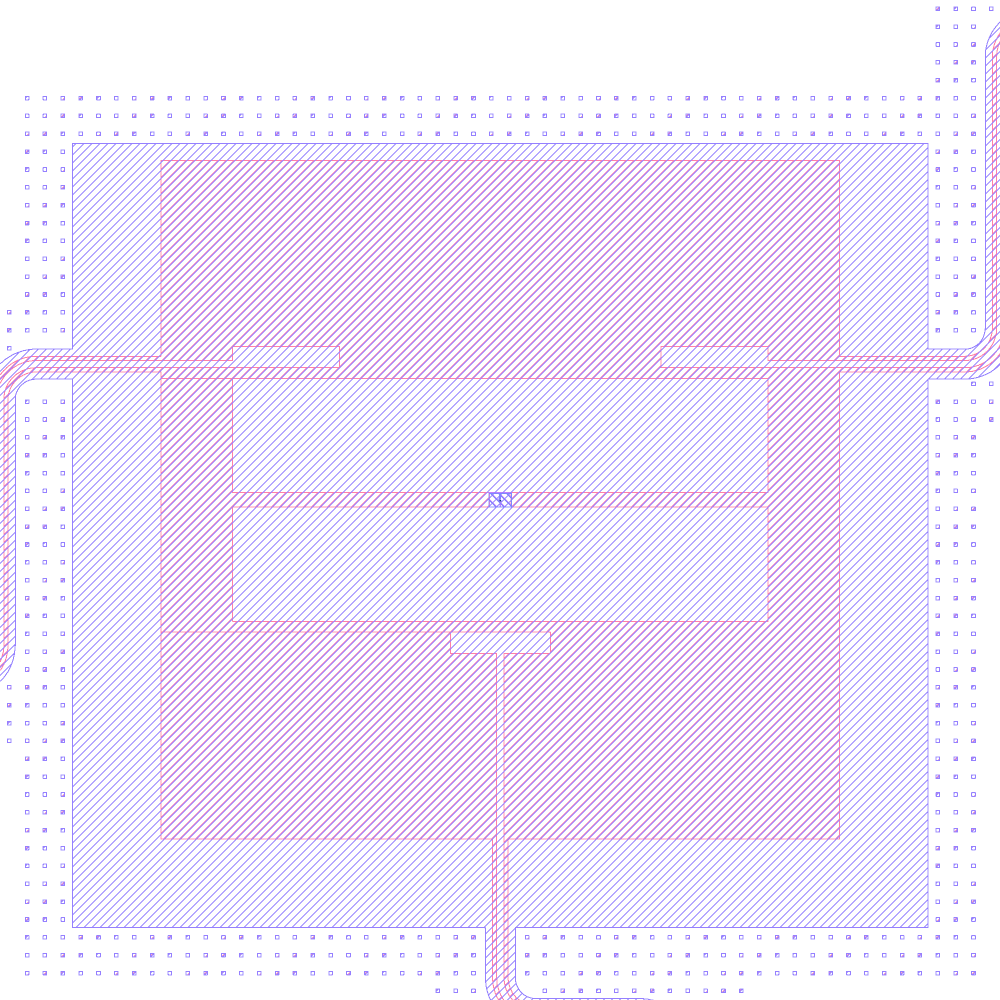

In [22]:
snap(d, OUT / "ibm_bowtie_5q.png", size=(1500, 1333))
snap(d, OUT / "ibm_bowtie_5q_triangle.png", box=(XC - DX - 700, YC - 1500, XC + 700, YC + 1900),
     size=(1200, 1450), width=520)
snap(d, OUT / "ibm_bowtie_5q_jj.png", box=(XC - 40, YC - 30, XC + 40, YC + 30), size=(800, 600), width=320)
snap(d, OUT / "ibm_bowtie_5q_cap.png", box=(XC - 400, 700, XC + 400, 1700), size=(800, 1000), width=320)
snap_file(Path("build") / "ibm_bowtie_5q_fab.oas", OUT / "ibm_bowtie_5q_cheese.png",
          box=(XC - 700, YC - 700, XC + 700, YC + 700), size=(1000, 1000), width=400);

## 16 · Summary

- **Matches the source:** the bowtie coupling graph, IBM's five qubit frequencies (within 23 MHz), the readout
  frequencies (1.6 % low: the Nb kinetic inductance entered the LOM after the lengths were set), the two bus frequencies
  (6.91 / 6.51 GHz for 7.0 / 6.6), J of the same order as IBM's (1.55–3.78 vs 1.24–2.01 MHz).
- **Changed by the PDK:** trilayer junctions in the 40–50 kΩ window, hence α ≈ −145 MHz (IBM −330 MHz; step 13 shows
  the two ways out); the 9 × 8 mm die and frame; pads 100 µm from the edges; the PDK band cheese (no original exists); content centred (no shift).
- **Open PDK design warnings:** none. The FEM jobs are exported, not solved (`RUN_FEM = False`).
- **Known limits:** the bus stubs are wires in the LOM (the eigenmode job holds them); a partial LOM selection that
  cuts a bus changes its resonator (the outer pairs are taken on the whole triangle for that reason).